# **Results, Limitations, and Learning Outcomes**

## **1. Data Preparation**

The original dataset contained **180,519 records and 53 features**. Entirely empty, highly incomplete, constant, redundant, or out-of-scope columns were removed, and the order month was extracted. Loss-making transactions and other commercially meaningful extremes were retained. The final dataset contained **180,519 records and 33 columns**, with three missing values in `Customer Zipcode`, which was excluded from numerical model inputs. Features were standardized where appropriate; in analyses with data partitions, scaling was fitted using training observations only.

## **2. Probabilistic Profiles with GMM**

**Gaussian Mixture Models**, fitted using EM, identified probabilistic profiles from sales, discount rate, profit ratio, and item quantity. Four components with diagonal covariance were selected for simplicity and interpretability, although more complex configurations achieved better probabilistic fit criteria.

**Final configuration:** `n_components=4`, `covariance_type="diag"`, `n_init=10`, `max_iter=300`, `tol=1e-4`, `reg_covar=1e-5`, and seed 42.

| Profile | Approximate validation share | Characteristics |
|---|---:|---|
| **0 — Mostly profitable single-item purchases** | 53% | One item per transaction, variable sales values, and predominantly positive profits. |
| **1 — Small two-item purchases** | 10% | Two items, sales typically around 100 and up to 200; mostly profitable transactions. |
| **2 — Loss-making transactions** | 5.8% | Negative profitability throughout the group; quantities between one and five items. |
| **3 — Mostly profitable multi-item purchases** | 30% | Three or more items and sales generally above 150; approximately 9.5% generate losses. |

**Interpretability:** these groups describe recognizable commercial profiles, although they represent transactions rather than permanent customer segments. Ten initializations improved mean partition stability: ARI increased from approximately **0.86 to 0.94**.

## **3. Dimensionality Reduction**

**Truncated SVD, PCA, and PPCA** were implemented, selecting five dimensions to summarize ten numerical features. Selection considered reconstruction, retained information, stability, and interpretability. PCA retained approximately **91.9% of variance**, halving dimensionality.

**Final configurations:**

- **SVD:** five components, `algorithm="arpack"`, and scaling without centering.
- **PCA:** five components, `svd_solver="full"`, and centered, standardized data.
- **PPCA:** five latent dimensions, estimated isotropic noise, and reconstruction using posterior means.

The methods recovered similar commercial themes: **transaction value, profitability, shipping duration, discounts, and the quantity–price relationship**. PCA and PPCA produced particularly similar interpretations; uncentered SVD combined some characteristics more strongly. Their broad themes were similar, but individual components were not identical.

**Interpretability:** dimensions could be associated with specific business characteristics, summarizing related features while retaining commercial meaning.

**LSA scope:** LSA was not implemented because the analysis focused on numerical order measurements rather than a text corpus. LSA applies Truncated SVD to term–document matrices, often weighted with TF–IDF, to recover latent semantic relationships. The distinction concerns application and data representation, rather than algorithms accepting only text or only continuous variables.

## **4. Latent Factors and Recommendation**

**FA and ICA** were used to identify interpretable factors and compare them with PCA.

**Final configurations:**

- **FA:** five factors, `varimax` rotation, `max_iter=3000`, `tol=1e-3`, and seed 42.
- **ICA:** five components, `algorithm="parallel"`, `whiten="unit-variance"`, `fun="logcosh"`, `max_iter=2000`, `tol=1e-4`, and seed 42.

**FA and ICA identified five highly similar themes:** transaction value, discount intensity, the price–quantity contrast, profitability, and shipping duration. Factor order, signs, and weights differed without necessarily changing their commercial meaning. PCA recovered comparable themes, although some components combined contributions from more features.

**Interpretability:** the factors supported meaningful business interpretations, but describe statistical associations rather than demonstrated causes of commercial behavior.

The reconstruction comparison shows that PCA and ICA achieved lower errors than FA with five dimensions:

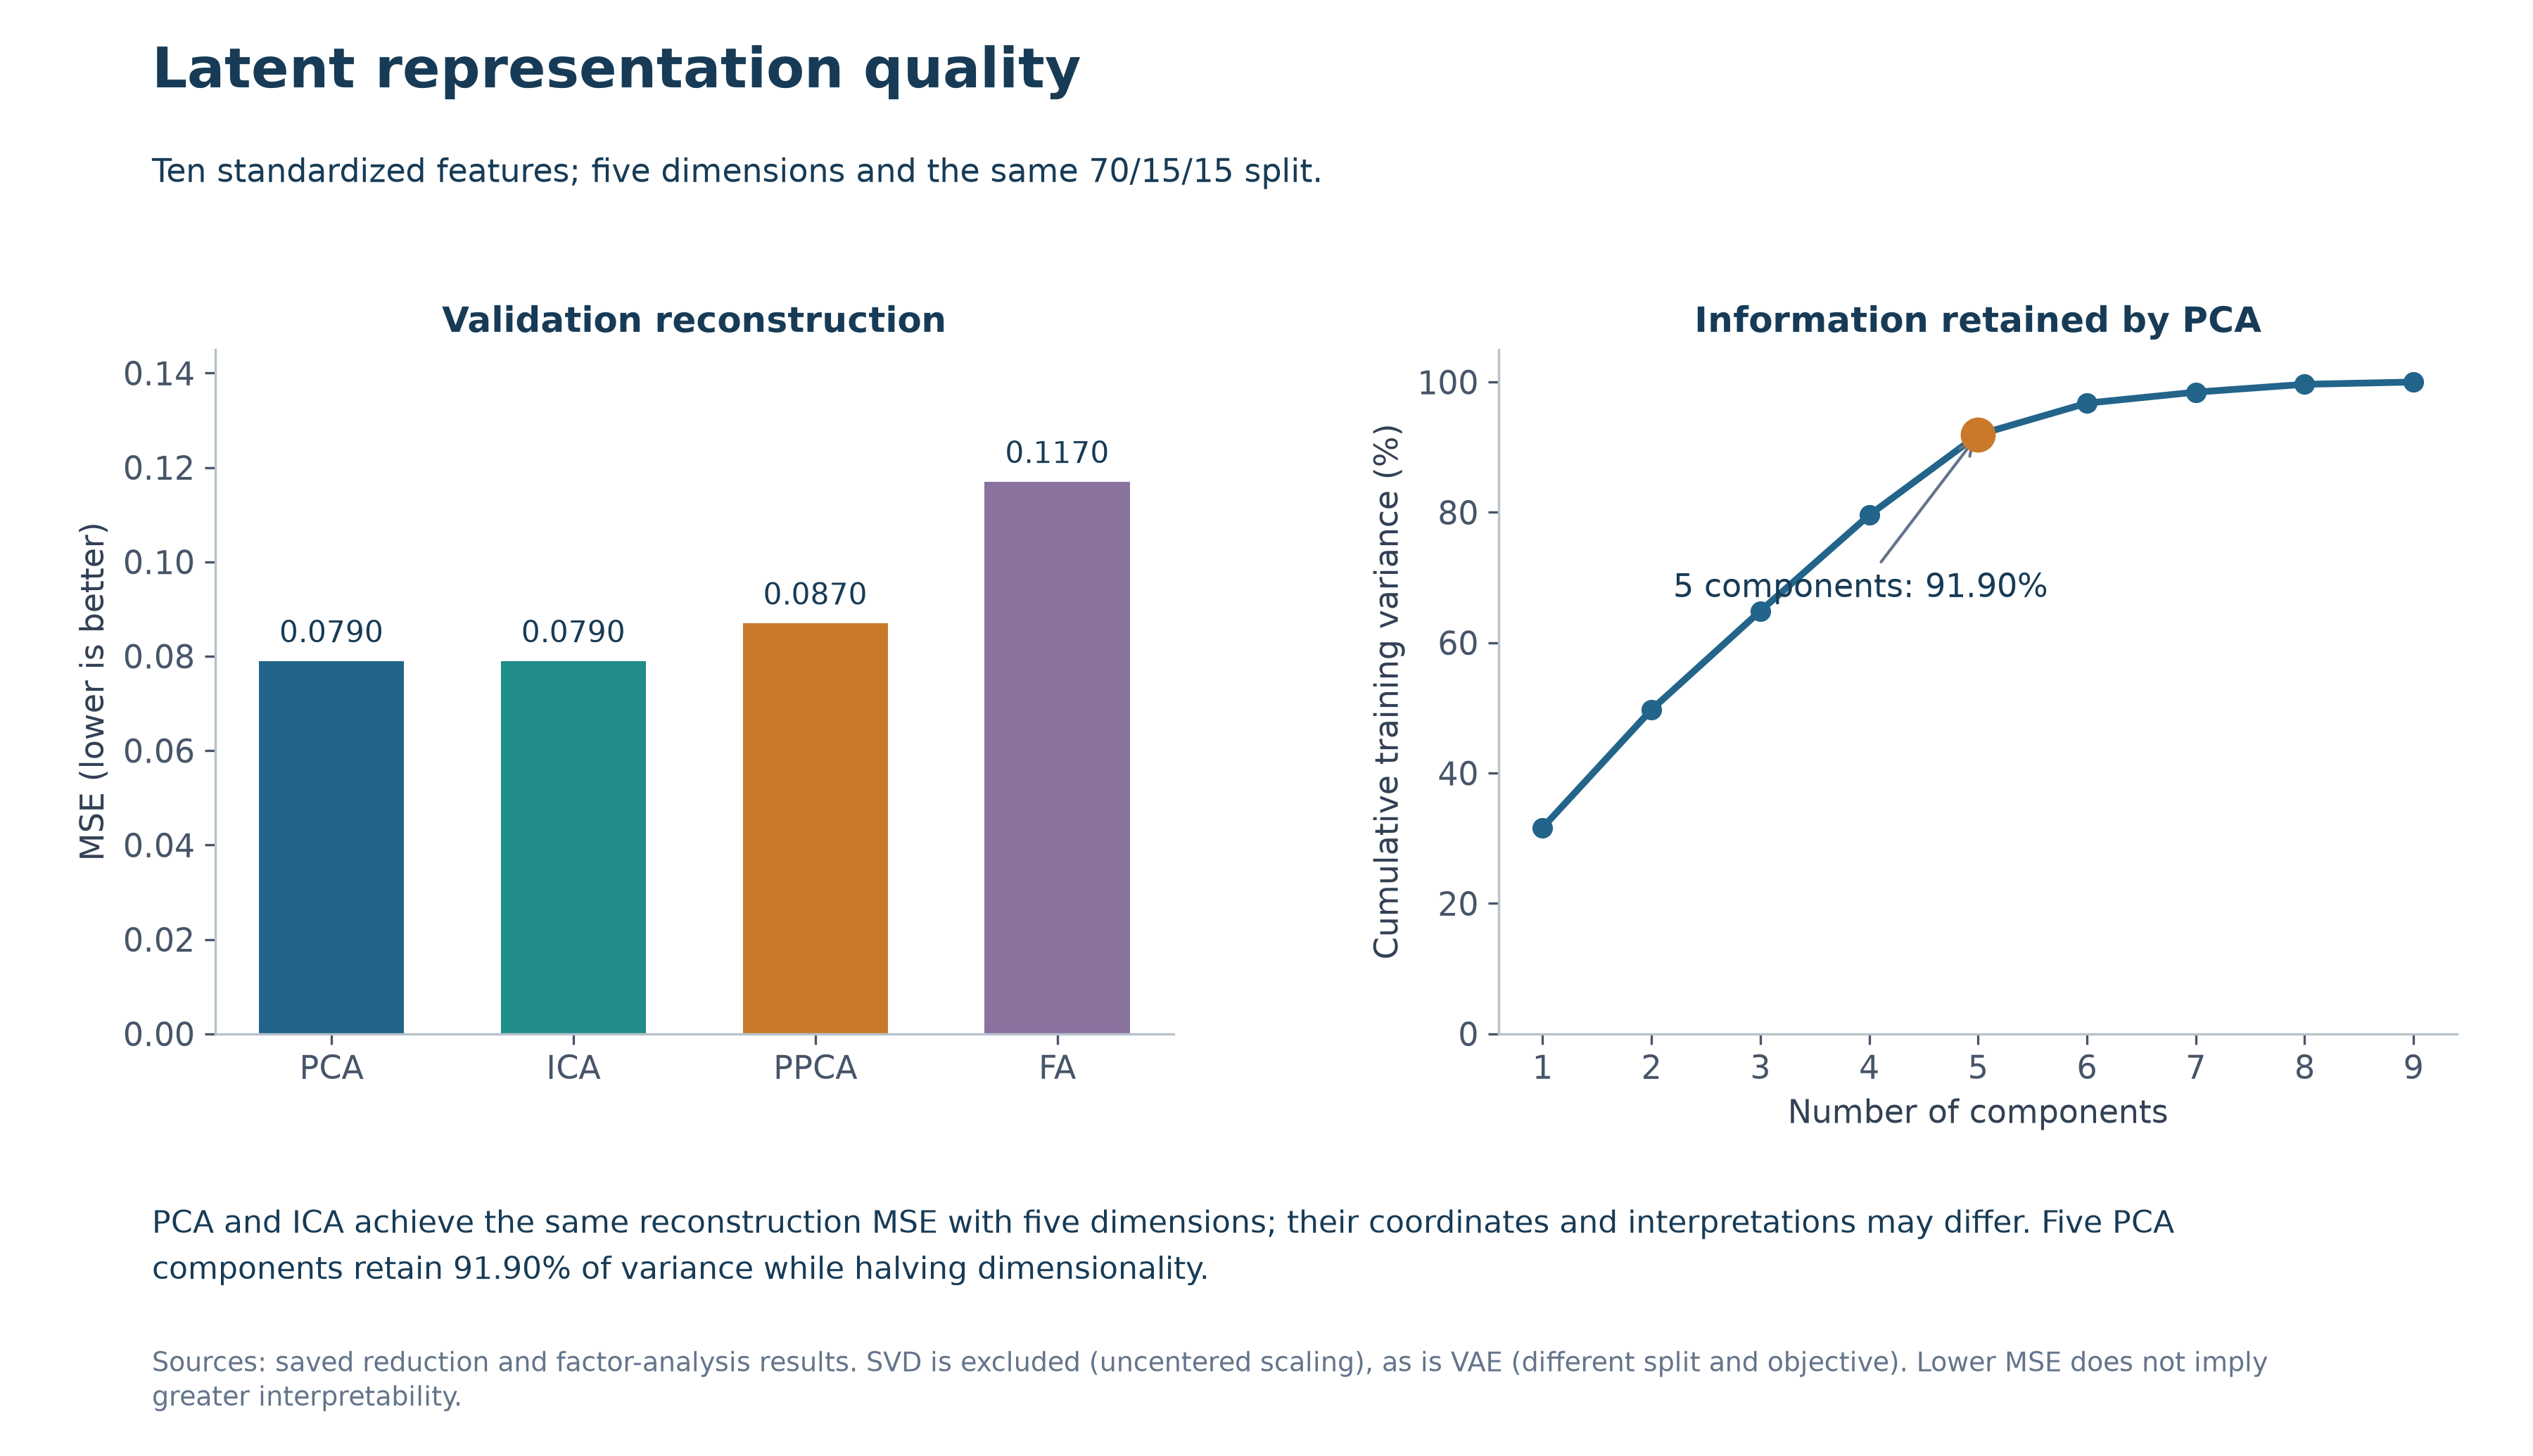

Lower reconstruction error does not necessarily imply greater interpretability. The comparison excludes SVD because of its uncentered scaling and AE because it uses a different split and objective.

A customer–product matrix was also constructed for an **SVD recommender with two factors, seed 42, and Top-10 recommendations**. Product interactions were strongly skewed: **the twenty most popular products accounted for approximately 82% of interactions**, while others had very few purchases.

| Model | Test HitRate@10 | Test NDCG@10 |
|---|---:|---:|
| **Popularity** | **0.8507** | **0.6572** |
| SVD, two factors | 0.8298 | 0.5810 |

For this dataset and evaluation, **popularity-based recommendation was more appropriate than the implemented SVD model**. Interaction concentration limited the information available to learn differentiated preferences, especially for infrequently purchased products.

## **5. Nonlinear Visualization**

t-SNE and UMAP represented relationships between orders described by numerical features in two dimensions.

**Final configurations:**

- **t-SNE:** two dimensions, `perplexity=30`, `learning_rate="auto"`, `init="random"`, and reference seed 42.
- **UMAP:** two dimensions, `n_neighbors=30`, `min_dist=0.1`, Euclidean distance, and reference seed 42.

**t-SNE better preserved local relationships**, retaining approximately **74% of the ten nearest neighbors**. Global distance preservation was limited, with Spearman around **0.13**. **Shipping Mode** produced the clearest segmentation, followed by localized concentrations for **Product Name** and **Category Name**. **Department Name** showed partial groupings with greater overlap.

**UMAP better preserved global relationships than the selected t-SNE configuration**, with Spearman around **0.315**, although global preservation remained limited. **Shipping Mode, Product Name, and Category Name** were most useful for interpreting regions. **Delivery Status** showed some partial concentrations but no clear overall separation.

**Interpretability:** both methods linked map regions to commercial and operational characteristics. Visual groupings do not automatically constitute validated clusters.

## **6. Anomaly Detection**

**Ten numerical features** were used to identify unusual transactions through complementary mechanisms.

| Model | Final configuration |
|---|---|
| **PCA — $T^2$/SPE** | Five components and `svd_solver="full"`. |
| **ICA — NLL/SPE** | Five components, `whiten="unit-variance"`, `max_iter=500`, `tol=1e-3`; Gaussian KDE with `bandwidth=0.3`, fitted on 5,000 training observations; seed 42. |
| **Mahalanobis** | Ten standardized features and Ledoit–Wolf regularized covariance. |
| **LOF** | Twenty neighbors, Euclidean distance, and `novelty=True`. |
| **Isolation Forest** | 400 trees, 1,024 observations per tree, `max_features=1.0`, `bootstrap=False`, and seed 42. |

All methods were evaluated using thresholds corresponding to the **95th and 99th percentiles of training scores**.

| Score | Flagged at $\alpha=0.05$ | Flagged at $\alpha=0.01$ |
|---|---:|---:|
| PCA — $T^2$ | 1,751 | 339 |
| PCA — SPE | 1,790 | 362 |
| ICA — NLL | 1,791 | 348 |
| ICA — SPE | 1,790 | 362 |
| Mahalanobis | 1,739 | 349 |
| LOF | 1,891 | 350 |
| Isolation Forest | 1,765 | 338 |

Counts refer to **36,104 validation observations** and should not be added together, since methods may flag the same transactions.

Detections included substantial losses, high sales or profits, and unusual operational characteristics. Anomalies may also arise from unusual combinations of individually non-extreme values. Therefore, **a statistical anomaly does not necessarily indicate an error, fraud, or adverse business outcome**.

**False positives and false negatives:** raising the threshold makes detection more restrictive and can increase false negatives; lowering it broadens detection and can increase false positives. These rates could not be measured without verified labels. The 5% and 1% levels are selection criteria, not known false-positive rates. Scores and threshold-based flags were generated without training a supervised classifier.

**$\alpha=0.05$ was considered a defensible exploratory choice** because it permits reviewing more cases and patterns, without establishing greater accuracy. Detections depend on both the threshold and the method's hyperparameters.

The following figure also includes VAE detections. PCA and ICA–SPE are grouped because their results coincide:

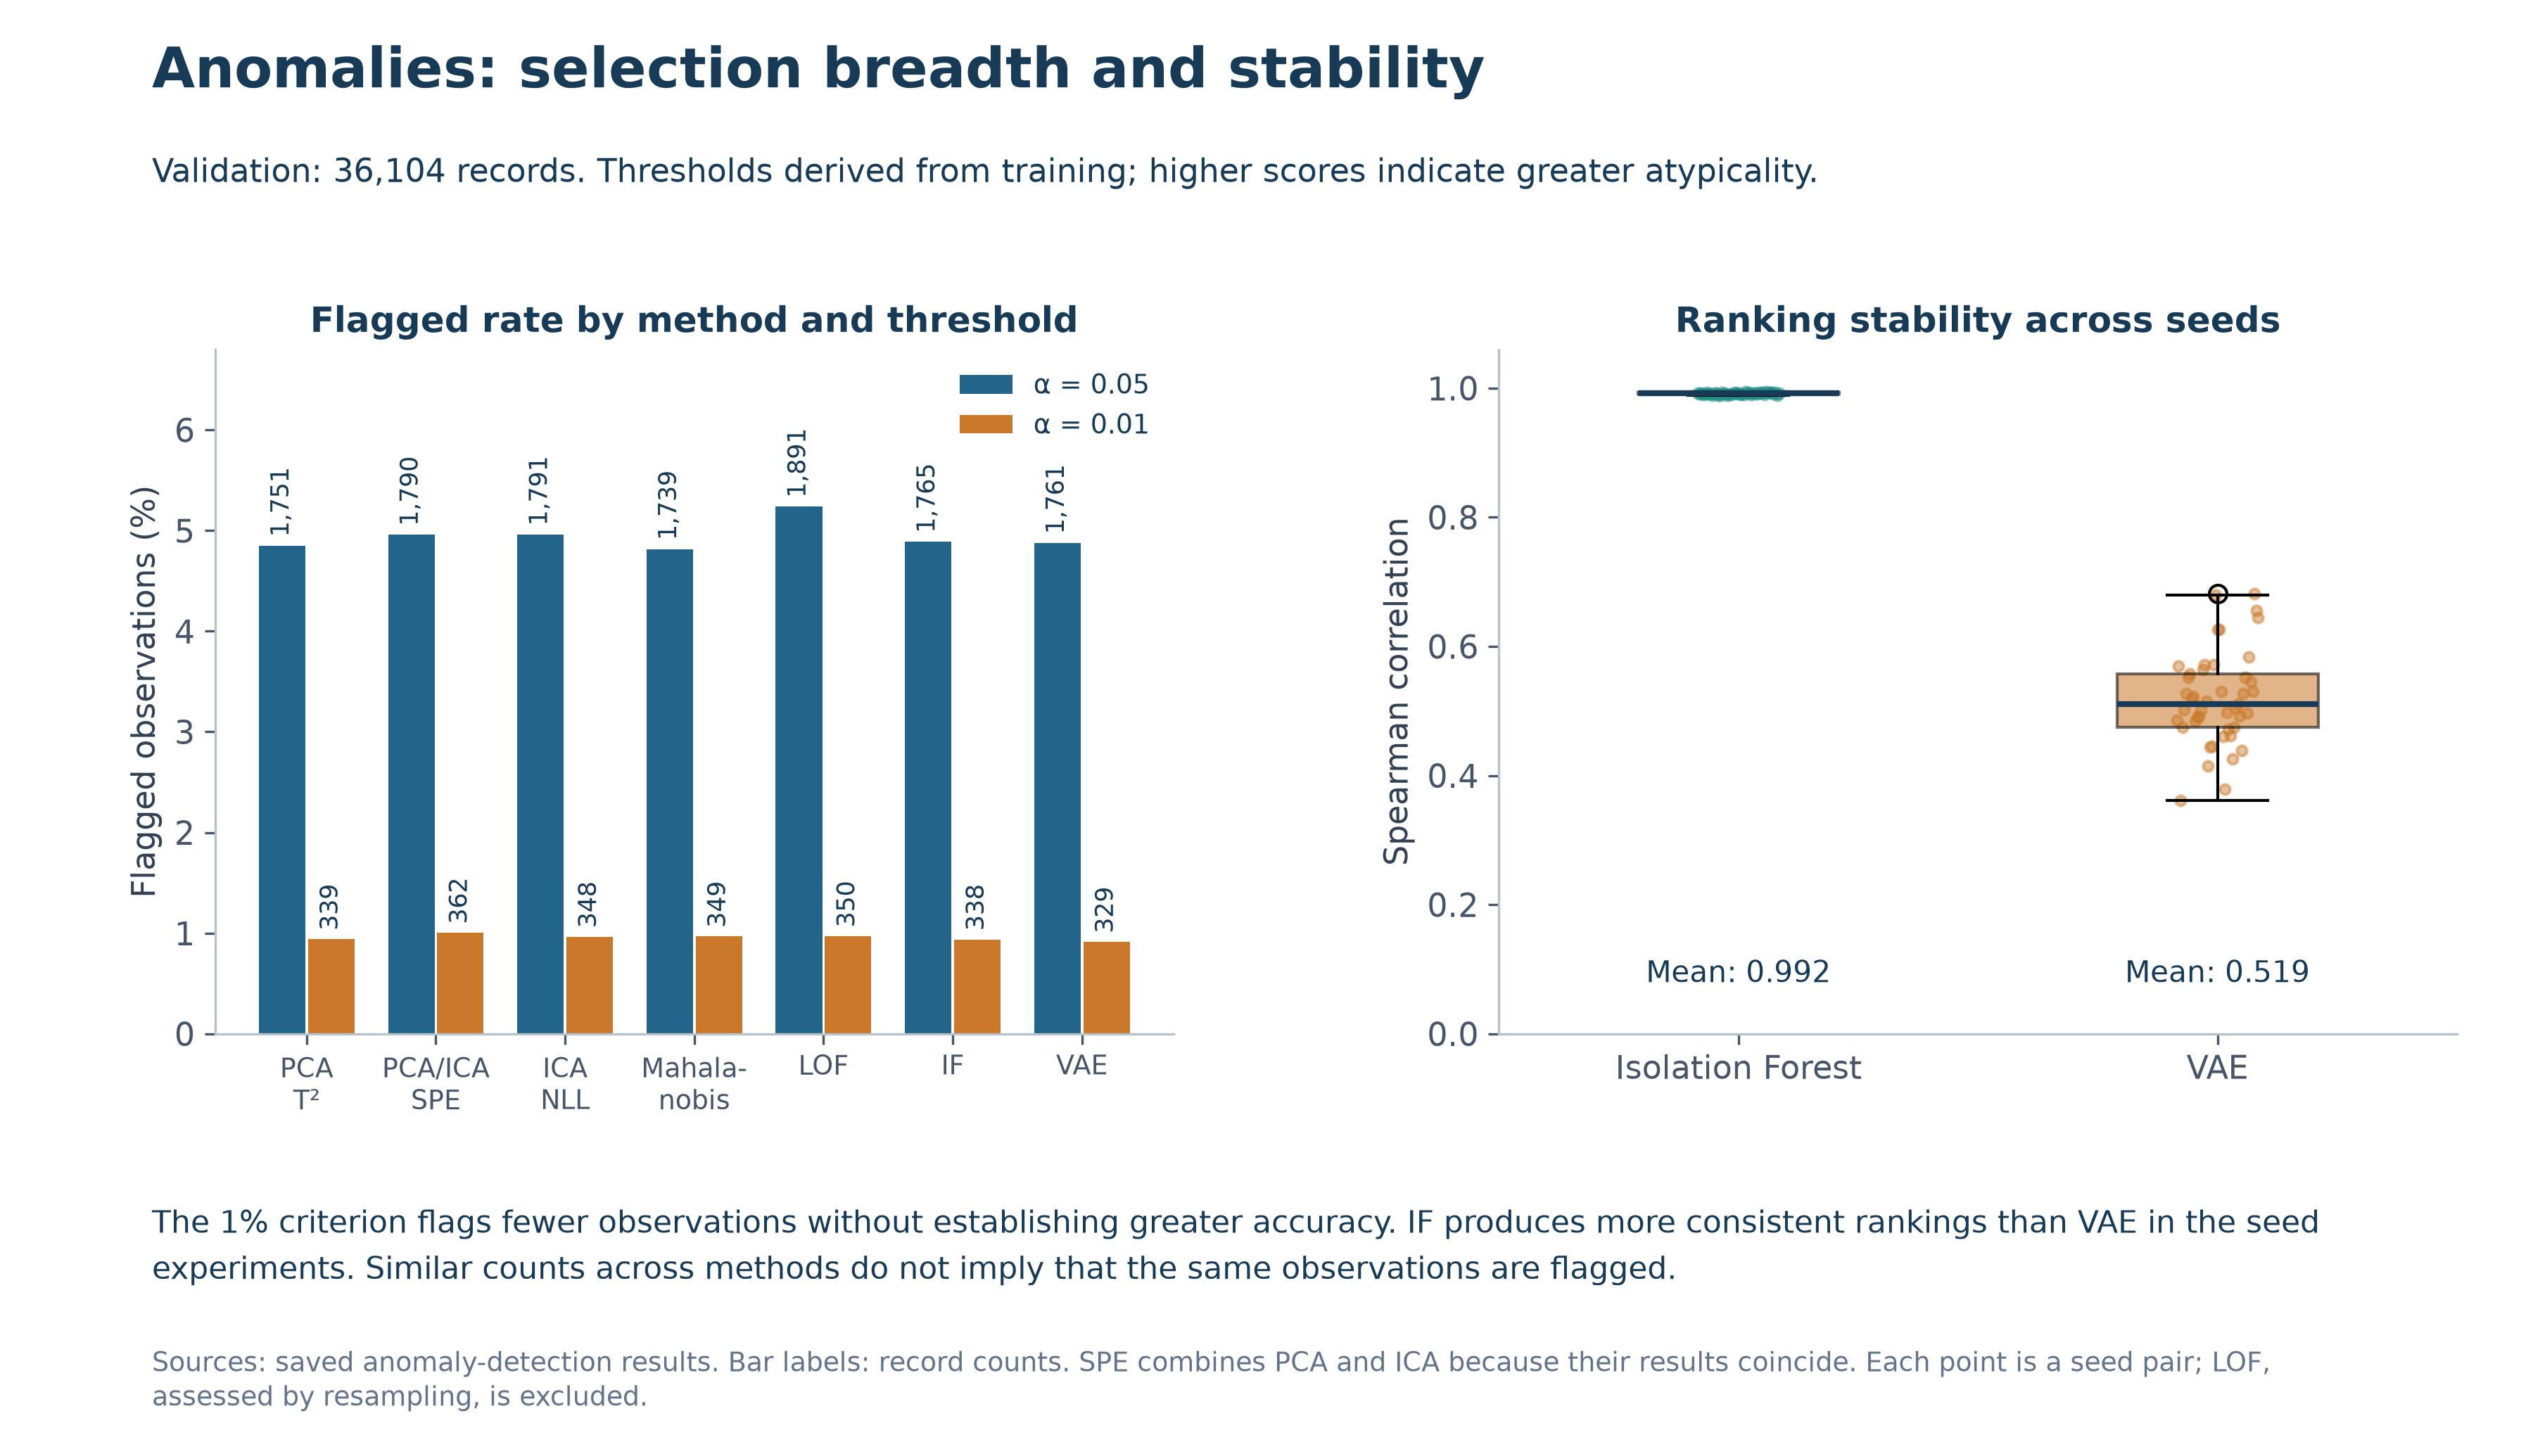

Future work should distinguish commercially beneficial and adverse anomalies and contextualize them using geographical, customer, product, and operational attributes.

## **7. Neural Networks, AE, and VAE**

The study covered neural-network fundamentals: neurons, weights, biases, activations, forward propagation, loss functions, backpropagation, and optimization. An **AE** learns a compressed representation to reconstruct inputs, whereas a **VAE** learns latent distributions and combines reconstruction with probabilistic regularization.

**Final configurations:**

- **AE:** five latent dimensions, hidden width 64, Adam, `learning_rate=0.001`, `batch_size=128`, maximum 100 epochs, patience 15, and minimum improvement `1e-6`.
- **VAE:** five latent dimensions, hidden width 64, Adam, `learning_rate=0.001`, $\beta=0.001$, `batch_size=256`, maximum 100 epochs, and patience 10.
- **Reference seed:** 42; ten seeds were used to evaluate stability.

AE dimensions supported the following interpretations:

| Dimension | Commercial interpretation |
|---|---|
| **AE1** | Greater discount intensity, accompanied by longer shipping durations and higher prices. |
| **AE2** | Higher quantities of lower-priced products, with some association with longer shipping durations. |
| **AE3** | Higher quantities of inexpensive products and shorter shipping durations. |
| **AE4** | Lower item quantities and sales values. |
| **AE5** | Greater profitability and shorter shipping durations, with secondary associations with higher sales and prices. |

**Interpretability:** these interpretations rely on correlations with original features; they are neither causal factors nor exact network contributions. Variability across seeds showed that accurate reconstruction does not guarantee identical latent representations.

The VAE flagged **1,761 observations at $\alpha=0.05$** and **329 at $\alpha=0.01$**, approximately **4.88% and 0.91%** of validation data. Flagged transactions included both losses and positive profits, alongside differences in sales, prices, discounts, and shipping. High reconstruction error indicates difficulty representing an observation, not confirmed economic harm.

## **8. Product Associations**

A binary customer–product matrix was built to analyze purchase-history associations. **Apriori used minimum support 0.05**, `use_colnames=True`, and `low_memory=True`; rules were generated with **minimum confidence 0.50** and subsequently filtered to **lift greater than 1**. FP-Growth could complement this analysis in future work.

The analysis produced **511 frequent itemsets and 9,206 rules**. The first ten rules partitioned the same nine products between antecedents and consequents, rather than describing ten independent product combinations.

| Rule | Confidence | Lift |
|---|---:|---:|
| 1 | 54.44% | 2.60 |
| 2 | 50.00% | 2.59 |
| 3 | 53.32% | 2.57 |
| 4 | 51.16% | 2.57 |
| 5 | 50.28% | 2.57 |
| 6 | 57.69% | 2.56 |
| 7 | 50.82% | 2.55 |
| 8 | 53.34% | 2.55 |
| 9 | 51.14% | 2.55 |
| 10 | 52.34% | 2.55 |

All had support of approximately **6.18%**. Confidence expresses the proportion of antecedent purchasers who also purchased the consequent; lift compares this frequency with the consequent's overall prevalence.

These measures can inform **promotions, cross-selling, and marketing campaigns**, but do not demonstrate that a campaign will generate additional sales. Since transactions represent customer histories, they do not establish that products were purchased in the same order or in a particular sequence.

## **9. Limitations**

- **No verified labels:** detection accuracy and false-positive/false-negative rates could not be measured.
- **Methodological sensitivity:** features, scaling, hyperparameters, seeds, and thresholds can change results.
- **Descriptive interpretability:** latent factors could be linked to business concepts but are not demonstrated causes. AE interpretations can also vary across runs.
- **Loss of context:** removing complete dates and order identifiers limits temporal and basket-level analysis.
- **Generalization:** results apply to this dataset and its partitions and do not guarantee equivalent future performance.

## **10. Identified Biases**

- **Feature selection in t-SNE and UMAP:** visual relationships depend on included features and their scaling. Adding or removing features can change neighbors and groupings. Maps provide one perspective on orders rather than all possible relationships. Categories added as colors support interpretation but were not inputs to the embedding.
- **Feature redundancy:** related monetary features may reinforce particular patterns in components, distances, and representations.
- **Popularity:** frequently purchased products dominate interactions and may favor both popular recommendations and frequent associations.
- **Activity and exposure:** customers with more purchases or longer observation periods have more opportunities to accumulate products in their histories.
- **Result selection:** prioritizing top rules, a single seed, or visually striking groups can omit alternative patterns.
- **Commercial coverage:** more represented countries, customers, and categories have greater influence on results.

## **11. Learning Outcomes**

The study developed skills in identifying probabilistic profiles using **GMM**, extracting and interpreting latent variables with **SVD, PCA, PPCA, FA, ICA, and AE**, and visualizing relationships in two dimensions using **t-SNE and UMAP**.

It also compared anomaly mechanisms: within-subspace deviation with **Hotelling $T^2$**, residual error with **SPE**, low density through **ICA–NLL**, multivariate distance with **Mahalanobis**, density contrasts with **LOF**, tree-based isolation with **Isolation Forest**, and reconstruction error with **VAE**.

Finally, it covered neural-network fundamentals, the operation of AE and VAE, and the interpretation of **support, confidence, and lift** to explore promotion, marketing, and cross-selling opportunities.

## **12. Future Work**

1. Explain individual anomalies through feature contributions and distinguish beneficial, adverse, and ambiguous cases using business criteria.
2. Contextualize profiles and anomalies by region, customer segment, product, and period.
3. Evaluate temporal stability and sensitivity to different feature sets.
4. Improve recommendation by considering diversity, coverage, and infrequently purchased products alongside accuracy.
5. Complement the analysis with FP-Growth and compare it with Apriori using equal parameters, results, runtime, and memory consumption.
6. Reduce rule redundancy and validate associations in later periods.
7. Evaluate promotions through experiments measuring incremental sales and profitability.
8. Examine anomalies recurring across seeds and methods to distinguish consistent detections from configuration-dependent ones.